# <font color = Blue> **Trabalho Final — Problema 05 - Gasolina EUA**

**`Objetivo do trabalho`**:  modelar um *problema real* e fazer predição utilizando os modelos de séries temporais estudados na disciplina.

**`Problema Real`**: Modelagem e predição de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária - **de 08/02/1991 a 20/01/2017**.

**`Tarefa`**: encontrar o melhor modelo e fazer a predição (**forecast**) de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária para um horizonte **`h`**, que será definido adiante.


## <font color = Blue> **Configuração Inicial e Carregamento da Série**
Vamos instalar/importar as bibliotecas necessárias e carregar a série temporal.

- **Bibliotecas básicas**

In [1]:
#Bibliotecas básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

- **Carregamento da Série `Gasolina EUA`**

Fonte e preparação: U.S. Energy Information Administration (EIA), série WGFUPUS2. Observações semanais, em milhões de barris/dia; indicador de oferta ao mercado, usado como aproximação da demanda. Calendário semanal alinhado às datas da EIA; o registro de 10/10/1997, ausente no XLS atual da EIA, foi preservado da série publicada fpp2::gasoline (8,221). Os demais valores coincidem integralmente. Fonte complementar: https://pkg.robjhyndman.com/fpp2/reference/gasoline.html . Fonte: https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=WGFUPUS2&f=W

O CSV será carregado diretamente do repositório GitHub `MiroPlacido/Datasets`: `AST_2026_Problema_05_Gasolina_EUA.csv`.


In [2]:
url = 'https://raw.githubusercontent.com/MiroPlacido/Datasets/refs/heads/main/AST_2026_Problema_05_Gasolina_EUA.csv'
df = pd.read_csv(url)

# Visualização do df
df.head()


,Data,Volume_Milhoes_Barris_Dia
0,1991-02-08,6.621
1,1991-02-15,6.433
2,1991-02-22,6.582
3,1991-03-01,7.224
4,1991-03-08,6.875


In [3]:
# Identificando a data e setando como índice
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

# Configurar frequência para SEMANAL (para evitar warnings de inferência)
df.index.freq = 'W-FRI'

# Visualizando
df.head()


,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


- **Plot da série ORIGINAL**

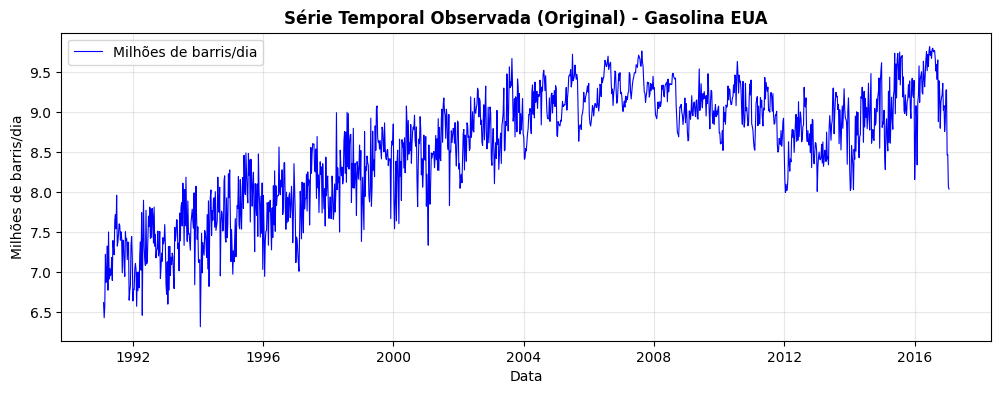

In [4]:
# Visualização da série
plt.figure(figsize=(12, 4))
plt.plot(df, label='Milhões de barris/dia', color='blue', linewidth=0.8)
plt.title('Série Temporal Observada (Original) - Gasolina EUA', fontweight = "bold")
plt.xlabel('Data')
plt.ylabel('Milhões de barris/dia')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()


## <font color = Blue> **Parte 1 - Divisão ($split$) da série temporal**


- **Defina e justifique o horizonte `h` de predição**.
- Um horizonte múltiplo do período sazonal `m` é conveniente;
- Reserve os **últimos `h` semanas para teste**, utilizando os dados anteriores como treino e validação;


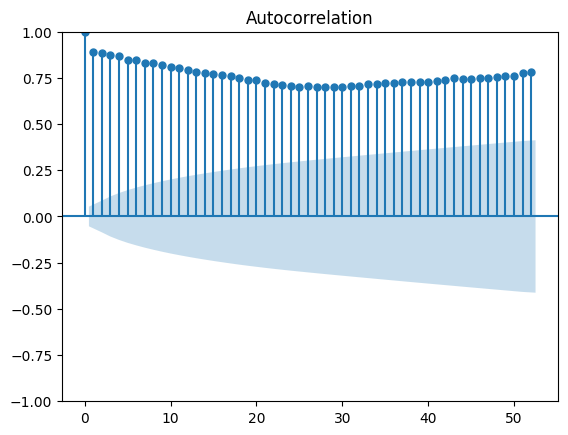

In [5]:
plot_acf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

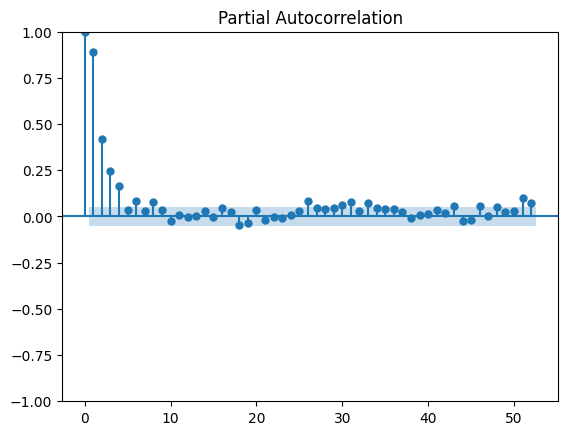

In [6]:
plot_pacf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

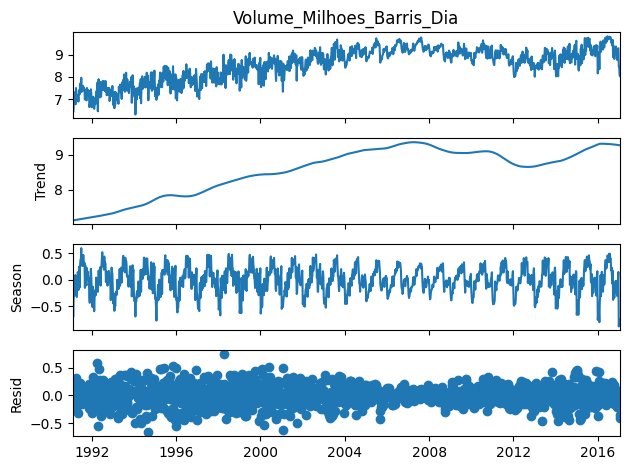

In [7]:
stl = STL(df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

Identificamos que a sazonalidade é de um ano. (52 semanas)

In [8]:
m = 52   # Período sazonal (semanas em um ano)
h = 52   # Horizonte de predição: 1 ciclo sazonal completo

train_df = df.iloc[:-h]
test_df = df.iloc[-h:]

print(f"Total: {len(df)} semanas")
print(f"Treino: {len(train_df)} semanas ({train_df.index.min().date()} a {train_df.index.max().date()})")
print(f"Teste: {len(test_df)} semanas ({test_df.index.min().date()} a {test_df.index.max().date()})")

Total: 1355 semanas
Treino: 1303 semanas (1991-02-08 a 2016-01-22)
Teste: 52 semanas (2016-01-29 a 2017-01-20)


- **Plot o split da série, isto é, os conjuntos de treino e teste**

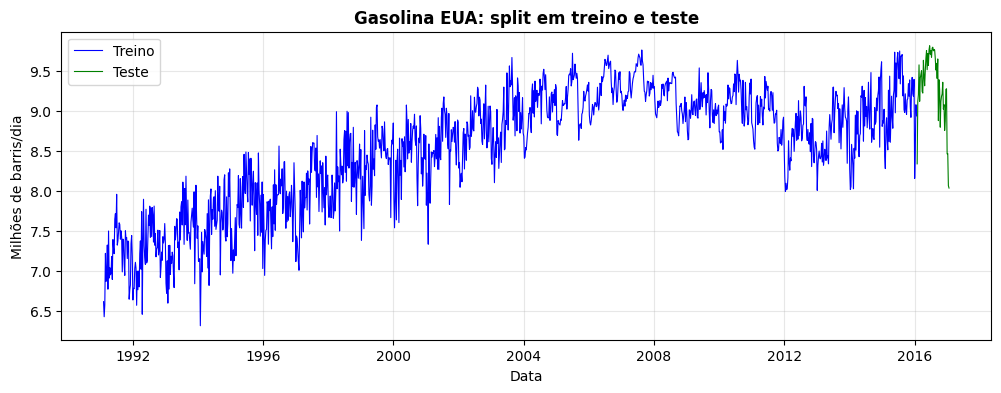

In [9]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df.Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste", color="green", linewidth=0.8)
plt.title("Gasolina EUA: split em treino e teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## <font color = Blue> **Parte 2 - Tratamento da Série (Detecção e tratamento de anomalias)**


Verifique se o conjunto de treino precisa de algum tratamento. Deixe clara sua escolha, explicando o motivo.
- **Obs:** a escolha pode ser "nada a ajustar".



In [10]:
train_df.head()

,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


In [11]:
train_df.isnull().sum()

,0
Volume_Milhoes_Barris_Dia,0


In [12]:
train_df.duplicated().sum()

np.int64(305)

In [13]:
df.describe(include='all')

,Volume_Milhoes_Barris_Dia
count,1355.000000
mean,8.553304
std,0.731086
min,6.321000
25%,8.049000
50%,8.713000
75%,9.121500
max,9.815000


In [14]:
serie_treino = train_df.Volume_Milhoes_Barris_Dia

print("Valores nulos:", serie_treino.isna().sum())
print("Datas duplicadas:", serie_treino.index.duplicated().sum())

# Verifica se todas as datas estão espaçadas de exatamente 7 dias
intervalos = serie_treino.index.to_series().diff().dropna()
print("Intervalos entre datas:", intervalos.value_counts().to_dict())

serie_treino.describe()

Valores nulos: 0
Datas duplicadas: 0
Intervalos entre datas: {Timedelta('7 days 00:00:00'): 1302}


,Volume_Milhoes_Barris_Dia
count,1303.000000
mean,8.523015
std,0.724014
min,6.321000
25%,8.016500
50%,8.684000
75%,9.090000
max,9.762000


Nada a ajustar.

## <font color = Blue> **Parte 3 - Análise e Diagnóstico**
- Faça plot de um período curto do conjunto de treino (trecho ampliado) para identificar visualmente sazonalidade;
- Faça análises de autocorrelação, estacionariedade e sazonalidade utilizando o conjunto de treino.


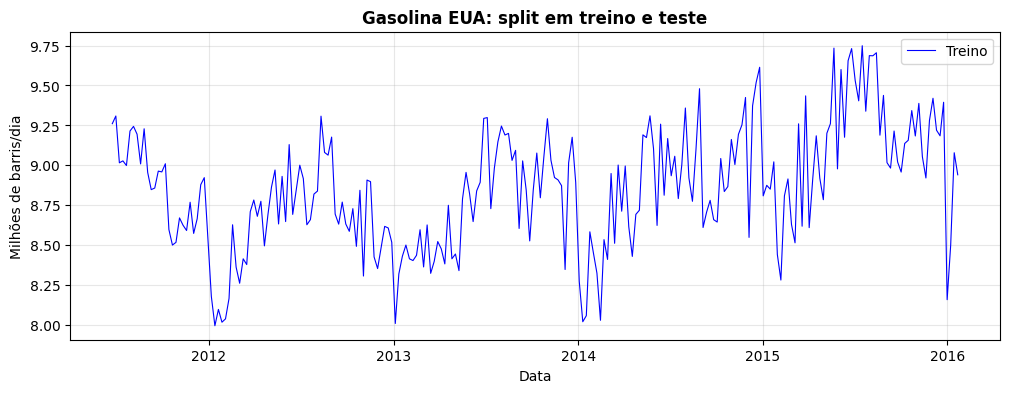

In [15]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df[-240:].Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.title("Gasolina EUA: split em treino e teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

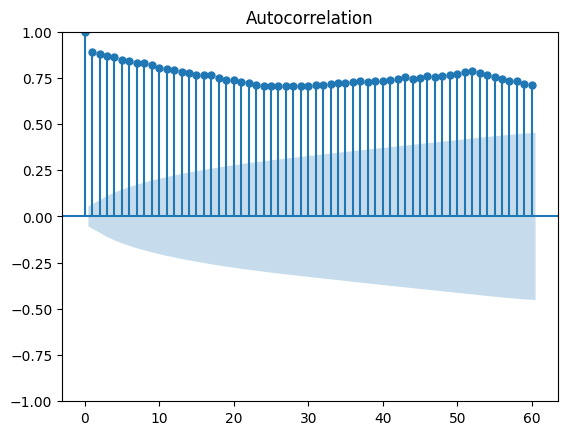

In [16]:
plot_acf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

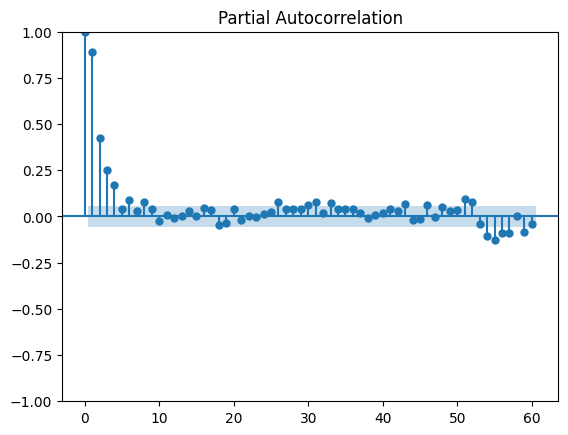

In [17]:
plot_pacf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

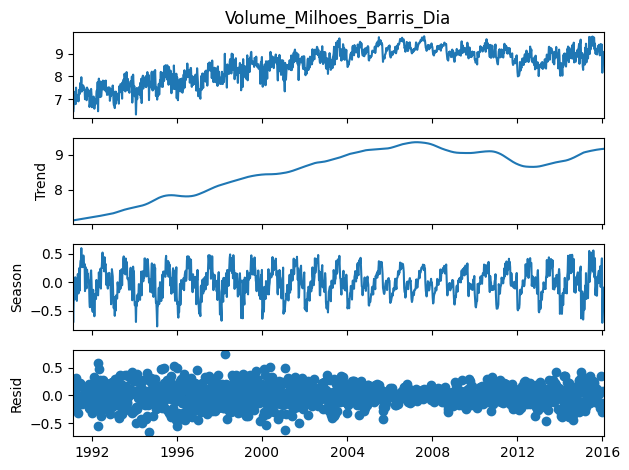

In [18]:
stl = STL(train_df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

In [19]:
adfuller(train_df.Volume_Milhoes_Barris_Dia.values, result_object=True)

ADFullerResult
ADF Statistic: -2.76068
P-value: 0.06411
Used Lag: 8
Nobs: 1294
Critical Values: {'1%': np.float64(-3.4354136163971782), '5%': np.float64(-2.8637761637845895), '10%': np.float64(-2.5679605492954045)}

## <font color = Blue> **Parte 4 - Treinamento e seleção do modelo**

- Compare **ETSModel, ARIMA, SARIMA, árvore de decisão, Prophet e LSTM**, *justificando eventual não aplicação*;
- Para seleção do modelo e seus hiperparâmetros, utilize **Cross Validation Temporal exclusivamente dentro do conjunto de treino**, com as mesmas janelas para todos os candidatos e blocos de validação de comprimento **`h`**;
- Selecione pelo **RMSE médio das janelas de validação**, calculado na escala original (milhões de barris por dia);
- Todos os modelos devem prever os **`h` períodos a partir da mesma origem**, sem utilizar valores reais do bloco previsto. Para árvore de decisão e LSTM, explicite a estratégia de previsão (recursiva, direta ou de múltiplas saídas).


In [20]:
dif1 = train_df.Volume_Milhoes_Barris_Dia.diff(1).dropna()
dif1.head()

,Volume_Milhoes_Barris_Dia
Data,
1991-02-15,-0.188
1991-02-22,0.149
1991-03-01,0.642
1991-03-08,-0.349
1991-03-15,0.072


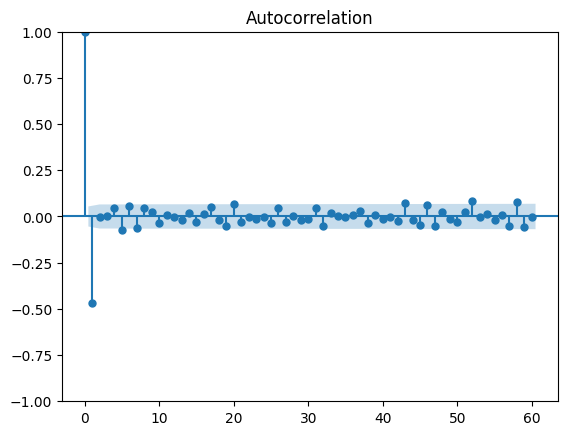

In [21]:
plot_acf(dif1, lags=60)
plt.show()

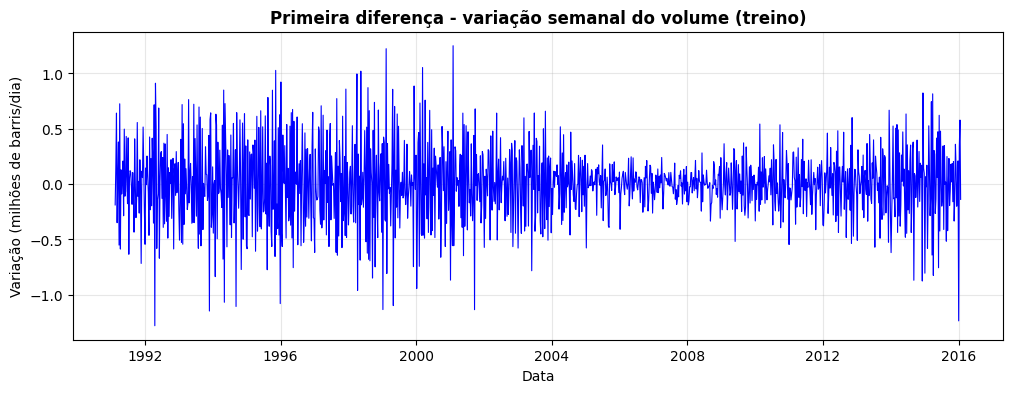

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(dif1, color="blue", linewidth=0.8)
plt.title("Primeira diferença - variação semanal do volume (treino)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Variação (milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.show()

### ETSModel

### SARIMA

In [23]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 9.4 MB/s  0:00:00


In [24]:
from pmdarima import auto_arima

In [ ]:
model = auto_arima(train_df.Volume_Milhoes_Barris_Dia, start_p = 1, start_q = 1, max_p = 4, max_q = 52, m = m, seasonal = True, start_P=1, start_Q=0, max_P=2,max_D = 1, trace= True, error_action="ignore", suppress_warnings=True, stepwise=True )

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,0)[52] intercept   : AIC=280.087, Time=35.14 sec
 ARIMA(0,1,0)(0,0,0)[52] intercept   : AIC=859.313, Time=0.15 sec
 ARIMA(1,1,0)(1,0,0)[52] intercept   : AIC=510.123, Time=12.70 sec
 ARIMA(0,1,1)(0,0,1)[52] intercept   : AIC=300.174, Time=15.36 sec
 ARIMA(0,1,0)(0,0,0)[52]             : AIC=857.349, Time=0.09 sec
 ARIMA(1,1,1)(0,0,0)[52] intercept   : AIC=357.929, Time=0.70 sec
 ARIMA(1,1,1)(2,0,0)[52] intercept   : AIC=238.719, Time=157.51 sec
 ARIMA(1,1,1)(2,0,1)[52] intercept   : AIC=inf, Time=315.89 sec
 ARIMA(1,1,1)(1,0,1)[52] intercept   : AIC=inf, Time=59.67 sec
 ARIMA(0,1,1)(2,0,0)[52] intercept   : AIC=239.551, Time=127.32 sec
 ARIMA(1,1,0)(2,0,0)[52] intercept   : AIC=502.354, Time=74.17 sec
 ARIMA(2,1,1)(2,0,0)[52] intercept   : AIC=240.663, Time=281.62 sec


### Árvore de Decisão

### Prophet

### LSTM

## <font color = Blue> **Parte 5 - Avaliação do modelo no conjunto de teste**

- **Treine o modelo escolhido em todo o conjunto de treino**;
- **Avalie o modelo (escolhido na Parte 4) no conjunto de teste**. Para isso:
  - Faça a predição dos **`h` semanas**, sem utilizar valores reais do teste para atualizar as previsões, e compare com os dados observados;
  - Inclua **intervalo de previsão de 95% quando o modelo oferecer esse recurso**; caso contrário, justifique sua ausência;
  - Calcule o **RMSE no conjunto de teste, na escala original**;
- Não utilize o resultado do teste para trocar ou reajustar a configuração do modelo escolhido.


## <font color = Blue> **Parte 6 - Predição (forecast)**

- **Após concluir a avaliação, treine o modelo escolhido na série completa (treino + teste)**, mantendo a configuração selecionada;
- **Faça a predição para os próximos `h` semanas**, incluindo plot e intervalo de previsão de 95% quando disponível; caso contrário, justifique sua ausência.
